<a href="https://colab.research.google.com/github/SaloMunoz1106/Reto-Analisis-Portafolio/blob/main/Exploracion_Activos_YahooFinance_Pandas_Valentina_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Explorando activos financieros con Python y pandas
## Análisis exploratorio de activos de un portafolio

En este laboratorio aprenderás a obtener datos financieros, explorarlos con **pandas**, transformarlos y encontrar información útil para analizar activos.

> **Idea clave:** primero observamos los datos, después calculamos y finalmente interpretamos.


## 🧭 Ruta de aprendizaje

**1. Conectar con los datos** → Yahoo Finance y tickers  
**2. Conocer la información** → DataFrame y estructura  
**3. Mirar antes de calcular** → exploración inicial  
**4. Seguir el comportamiento** → precios y gráficos  
**5. Medir los cambios** → rendimientos  
**6. Describir lo encontrado** → estadísticas  
**7. Comparar para comprender** → varios activos  
**8. Buscar relaciones** → correlación  
**9. Tu análisis** → misión individual


# 1. 🔌 Conectar con los datos

### ¿De dónde obtenemos la información?

Yahoo Finance contiene información histórica de diferentes activos financieros. Para acceder a ella desde Python utilizaremos **yfinance**.

Un **ticker** es el código utilizado para identificar un activo. Por ejemplo: `AAPL`, `MSFT`, `AMZN` o `GOOGL`.


In [1]:
!pip -q install yfinance

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Nuestro primer activo

Comencemos con Apple. Más adelante cambiaremos el ticker para trabajar con los activos asignados.

In [3]:
ticker = "AAPL"

datos = yf.download(
    ticker,
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=False
)

datos.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2020-01-02,72.271545,75.087502,75.150002,73.797501,74.059998,135480400
2020-01-03,71.568916,74.357498,75.144997,74.125000,74.287498,146322800
2020-01-06,72.139214,74.949997,74.989998,73.187500,73.447502,118387200
2020-01-07,71.799919,74.597504,75.224998,74.370003,74.959999,108872000
2020-01-08,72.954918,75.797501,76.110001,74.290001,74.290001,132079200


# 2. 🧩 Conocer la información

Lo que acabamos de obtener es un **DataFrame de pandas**: una estructura de datos organizada en filas y columnas.

Antes de analizar, necesitamos saber qué contiene la tabla y cómo está organizada.


In [4]:
datos.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2020-01-02,72.271545,75.087502,75.150002,73.797501,74.059998,135480400
2020-01-03,71.568916,74.357498,75.144997,74.125000,74.287498,146322800
2020-01-06,72.139214,74.949997,74.989998,73.187500,73.447502,118387200
2020-01-07,71.799919,74.597504,75.224998,74.370003,74.959999,108872000
2020-01-08,72.954918,75.797501,76.110001,74.290001,74.290001,132079200


In [5]:
datos.tail()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2024-12-24,256.339783,258.200012,258.209991,255.289993,255.490005,23234700
2024-12-26,257.153778,259.019989,260.100006,257.630005,258.190002,27237100
2024-12-27,253.748550,255.589996,258.700012,253.059998,257.829987,42355300
2024-12-30,250.382950,252.199997,253.500000,250.750000,252.229996,35557500
2024-12-31,248.615799,250.419998,253.279999,249.429993,252.440002,39480700


In [6]:
datos.shape

(1258, 6)

In [7]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1258 entries, 2020-01-02 to 2024-12-31
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, AAPL)  1258 non-null   float64
 1   (Close, AAPL)      1258 non-null   float64
 2   (High, AAPL)       1258 non-null   float64
 3   (Low, AAPL)        1258 non-null   float64
 4   (Open, AAPL)       1258 non-null   float64
 5   (Volume, AAPL)     1258 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 68.8 KB


### 🧠 Piensa

- ¿Qué representa una fila?
- ¿Qué representa una columna?
- ¿Qué información contiene el índice?
- ¿Cuántas observaciones tenemos?

Estas preguntas forman parte del **análisis exploratorio de datos**.

# 3. 🔎 Mirar antes de calcular

Una exploración inicial nos ayuda a detectar características, diferencias o posibles problemas antes de comenzar a realizar cálculos.

In [8]:
datos.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
count,1258.000000,1258.000000,1258.000000,1258.000000,1258.000000,1.258000e+03
mean,151.247344,154.108800,155.660348,152.379123,153.951948,9.057103e+07
std,41.815935,41.520877,41.654310,41.305929,41.466618,5.324438e+07
min,54.117031,56.092499,57.125000,53.152500,57.020000,2.323470e+07
25%,126.170311,129.624996,130.755005,127.505001,129.017506,5.546825e+07
50%,149.839401,152.805000,154.570000,150.825005,152.575005,7.628335e+07
75%,175.750446,178.850006,180.160000,177.115005,178.500004,1.077425e+08
max,257.153778,259.019989,260.100006,257.630005,258.190002,4.265100e+08


In [9]:
datos.isna().sum()

,,0
Price,Ticker,
Adj Close,AAPL,0
Close,AAPL,0
High,AAPL,0
Low,AAPL,0
Open,AAPL,0
Volume,AAPL,0


### 🧠 Interpreta

No basta con ejecutar `describe()`. Observa los resultados y piensa: ¿qué nos permite conocer cada medida sobre los datos?

# 4. 📈 Seguir el comportamiento

Comencemos observando el precio de cierre. Una gráfica puede ayudarnos a identificar tendencias y cambios que serían difíciles de observar en una tabla.

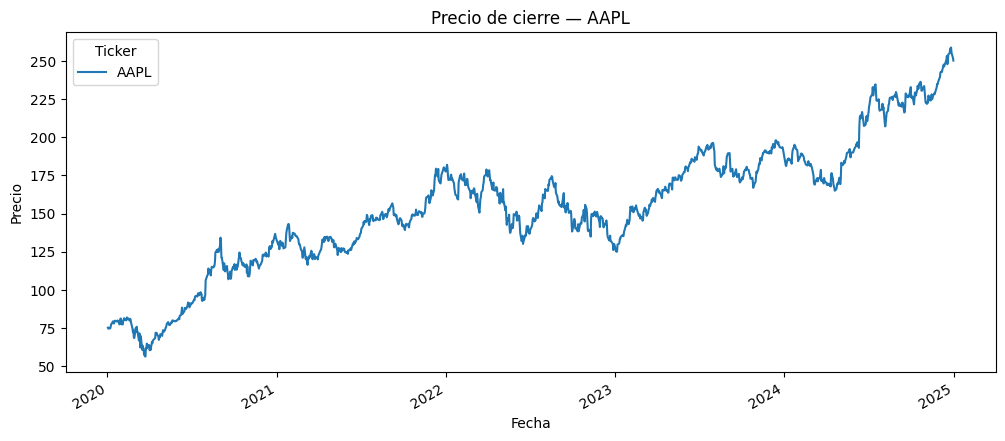

In [10]:
cierre = datos["Close"]

cierre.plot(figsize=(12, 5))
plt.title(f"Precio de cierre — {ticker}")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.show()

### 👀 Observa

Describe brevemente lo que encuentras:

- ¿Se observan períodos de crecimiento o disminución?
- ¿Hay cambios especialmente fuertes?
- ¿El comportamiento parece estable durante todo el período?


# 5. 🔄 Medir los cambios

Comparar solamente precios puede ser insuficiente porque los activos pueden comenzar con valores muy diferentes.

Una alternativa es estudiar los **rendimientos**, que expresan el cambio de una observación respecto a la anterior.


### Cálculo de Rendimientos Financieros

Existen dos formas principales de calcular los rendimientos financieros: discretos y logarítmicos.

#### 1. Rendimientos Discretos (o Simples)

Los rendimientos discretos representan el cambio porcentual en el precio de un activo entre dos períodos consecutivos. Son intuitivos y fáciles de interpretar, ya que reflejan directamente la ganancia o pérdida en relación con el precio inicial. Son adecuados para el cálculo de rendimientos de un solo período.

La fórmula para el rendimiento discreto $R_t$ en el período $t$ es:

$$\Large R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$

Donde:
*   $P_t$ es el precio del activo en el tiempo $t$.
*   $P_{t-1}$ es el precio del activo en el tiempo $t-1$.

### Ejemplo de Cálculo de Rendimientos

Consideremos los siguientes precios:
*   Precio Anterior ($P_{t-1}$): **100**
*   Precio Actual ($P_t$): **110**

#### 1. Cálculo del Rendimiento Discreto

Utilizando la fórmula:

$$\Large R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{110 - 100}{100} = \frac{10}{100} = 0.10$$

El rendimiento discreto es **0.10** o **10%**.


In [11]:
rendimiento = cierre.pct_change()
rendimiento.head()

Ticker,AAPL
Date,
2020-01-02,NaN
2020-01-03,-0.009722
2020-01-06,0.007968
2020-01-07,-0.004703
2020-01-08,0.016086


El primer valor aparece como `NaN` porque no existe una observación anterior con la cual compararlo.


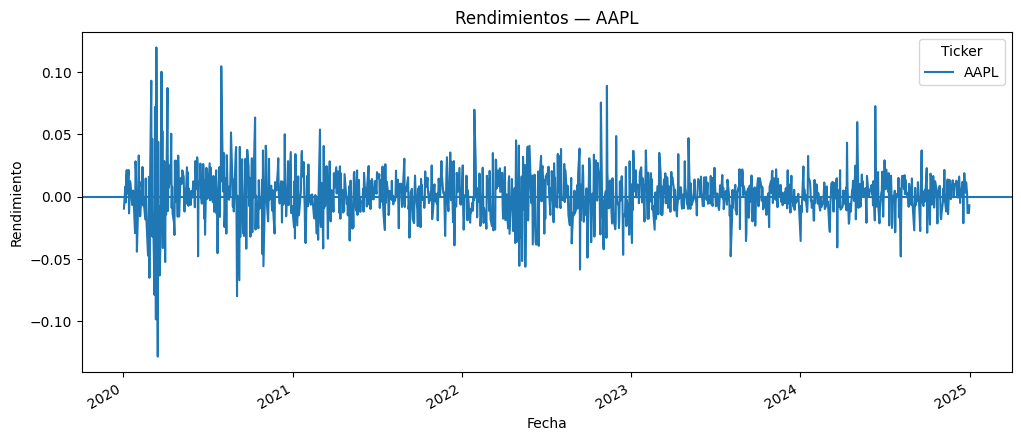

In [12]:
rendimiento.plot(figsize=(12, 5))

plt.axhline(0)
plt.title(f"Rendimientos — {ticker}")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento")
plt.show()

# 6. 📐 Describir lo encontrado

Ahora podemos utilizar las estadísticas descriptivas para conocer mejor la distribución de los rendimientos.

In [13]:
rendimiento.describe()

Ticker,AAPL
count,1257.000000
mean,0.001157
std,0.019957
min,-0.128647
25%,-0.008425
50%,0.001172
75%,0.011989
max,0.119808


### Interpretación de las Estadísticas Descriptivas de Rendimientos

Al analizar la tabla de estadísticas descriptivas para los rendimientos, observamos lo siguiente:

*   **Promedio (Mean):** El promedio de los rendimientos es cercano a cero (aproximadamente 0.1157%). Esto sugiere que, a lo largo del periodo analizado, el rendimiento diario promedio del activo ha sido muy bajo, lo cual es común en series de rendimientos diarios que no muestran una tendencia marcada a largo plazo.

*   **Desviación Estándar (Std):** La desviación estándar es de aproximadamente 1.99%. Esta medida nos indica la dispersión o volatilidad de los rendimientos diarios. Un valor del 2% diario significa que, en promedio, los rendimientos suelen desviarse en un 2% (ya sea al alza o a la baja) de la media. En el contexto financiero, una mayor desviación estándar implica una mayor volatilidad y, por ende, un mayor riesgo.

*   **Mínimo (Min):** El rendimiento mínimo observado es de aproximadamente -12.86%. Esto representa la mayor pérdida porcentual experimentada por el activo en un solo día durante el periodo. Si se hubieran invertido 100 pesos, una pérdida del 12.86% implicaría que el valor de la inversión se reduciría a 87.14 pesos en ese día.

*   **Máximo (Max):** El rendimiento máximo observado es de aproximadamente 11.98%. Esta es la mayor ganancia porcentual en un solo día. Es notable que la máxima pérdida (-12.86%) es ligeramente superior a la máxima ganancia (11.98%), lo que podría indicar una asimetría en los movimientos extremos del activo, con pérdidas más severas en ciertos días.

*   **Percentil 25% (Q1):** El primer cuartil es de -0.84%. Esto significa que el 25% de los días, el rendimiento del activo fue igual o inferior a -0.84%, lo que implica una pérdida para el 25% de las observaciones.

*   **Percentil 50% (Mediana):** La mediana (percentil 50%) es de aproximadamente 0.1172%. Esto indica que el 50% de los rendimientos fueron iguales o inferiores a este valor, y el otro 50% fueron iguales o superiores. Al ser cercano a cero y ligeramente positivo, refuerza la idea de que los rendimientos oscilan alrededor de cero.

*   **Percentil 75% (Q3):** El tercer cuartil es de 1.19%. Esto significa que el 75% de los días, el rendimiento del activo fue igual o inferior a 1.19%, o dicho de otra forma, el 25% de los días la rentabilidad fue superior a 1.19%.

**Ausencia de tendencia y oscilación alrededor de cero:** Esto es típico en las series de rendimientos de activos. A diferencia de los precios, que suelen mostrar tendencias alcistas o bajistas a largo plazo, los rendimientos diarios (o periódicos) tienden a fluctuar en torno a su promedio (que a menudo es cercano a cero). Esto indica que, en el corto plazo, los movimientos positivos y negativos se compensan, sin una dirección clara y sostenida.

**Dispersión alrededor de cero y su variabilidad (Volatilidad)**: Has identificado correctamente que la dispersión de los rendimientos alrededor de cero no es constante. Esta dispersión se mide con la desviación estándar, y en el ámbito financiero se conoce como volatilidad. Una mayor dispersión (picos más altos o valles más profundos) significa mayor volatilidad, lo que implica que el precio del activo está experimentando cambios más grandes en un corto período de tiempo. Los periodos de "alta dispersión" se correlacionan con alta volatilidad (mayor riesgo), mientras que los de "baja dispersión" indican baja volatilidad (menor riesgo).

**Rangos de máximos y mínimos (Variabilidad Extrema):** La observación de que los rendimientos máximos superan el 10% y los mínimos caen por debajo del -10% es crucial. Esto te da una idea del rango extremo de movimientos que el activo ha experimentado en un solo día. Rendimientos tan altos o tan bajos en un solo día son eventos significativos que reflejan la magnitud de los shocks o noticias que afectaron al activo en esos momentos.

# Percentiles extremos


In [14]:
print("Percentil 1:", rendimiento.quantile(0.01))
print("Percentil 5:", rendimiento.quantile(0.05))

Percentil 1: Ticker
AAPL   -0.050317
Name: 0.01, dtype: float64
Percentil 5: Ticker
AAPL   -0.030125
Name: 0.05, dtype: float64


## Interpretación de Percentiles como Pérdida Máxima Esperada (VaR)

Los percentiles 1 y 5 de los rendimientos son a menudo interpretados en el contexto de **Valor en Riesgo (VaR)**, una medida clave en finanzas para cuantificar la pérdida potencial de una inversión.

*   El **percentil 1** de aproximadamente -0.050317 (-5.03%) significa que existe un **1% de probabilidad** de que el activo experimente una pérdida de 5.03% o más de su valor en un día determinado, bajo condiciones normales de mercado. Esto se puede entender como la **máxima pérdida esperada** que el activo podría sufrir con un nivel de confianza del 99% (es decir, hay solo un 1% de posibilidades de que la pérdida real sea mayor).

*   El **percentil 5** de aproximadamente -0.030125 (-3.01%) significa que existe un **5% de probabilidad** de que el activo experimente una pérdida de 3.01% o más de su valor en un día determinado. Esto se interpreta como la **máxima pérdida esperada** con un nivel de confianza del 95% (hay un 5% de posibilidades de que la pérdida real sea mayor).

En resumen, estos valores proporcionan una estimación de las pérdidas extremas que un inversor podría enfrentar con este activo en un día, junto con la probabilidad de que ocurran.

In [15]:
print("Promedio:", rendimiento.mean())
print("Desviación estándar:", rendimiento.std())
print("Mínimo:", rendimiento.min())
print("Máximo:", rendimiento.max())

Promedio: Ticker
AAPL    0.001157
dtype: float64
Desviación estándar: Ticker
AAPL    0.019957
dtype: float64
Mínimo: Ticker
AAPL   -0.128647
dtype: float64
Máximo: Ticker
AAPL    0.119808
dtype: float64


### 🧠 Interpreta

¿Qué nos dice el promedio? ¿Qué información aporta la desviación estándar? ¿Qué representan los valores mínimo y máximo?

Recuerda: **una estadística tiene sentido cuando podemos explicar qué significa en el contexto financiero.**

# 7. ⚖️ Comparar para comprender

Ahora incorporaremos varios activos. La comparación nos permitirá observar diferencias en su comportamiento.

In [16]:
activos = ["AAPL", "MSFT", "AMZN"]

datos = yf.download(
    activos,
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=False
)

precios = datos["Close"]
precios.head()

[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,AMZN,MSFT
Date,,,
2020-01-02,75.087502,94.900497,160.619995
2020-01-03,74.357498,93.748497,158.619995
2020-01-06,74.949997,95.143997,159.029999
2020-01-07,74.597504,95.343002,157.580002
2020-01-08,75.797501,94.598503,160.089996


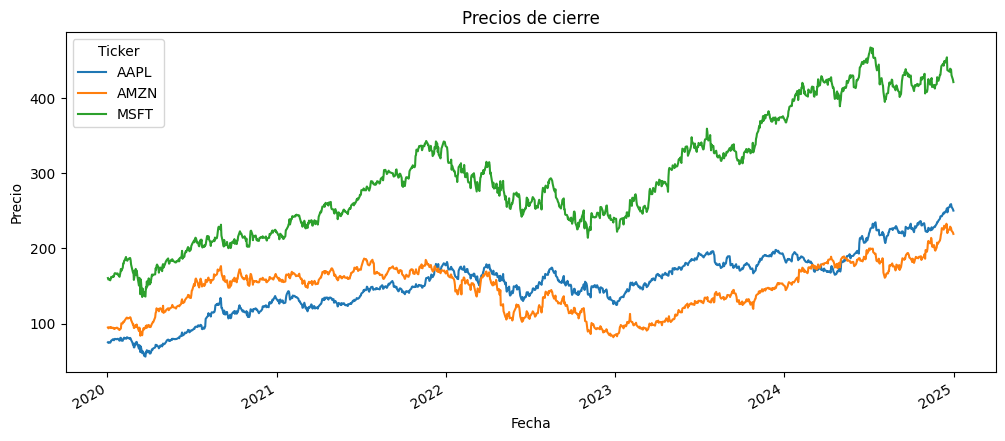

In [17]:
precios.plot(figsize=(12, 5))

plt.title("Precios de cierre")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.show()

Los precios pueden tener escalas diferentes. Para comparar su evolución desde un mismo punto de referencia podemos construir un índice base 100.

### Normalización de Precios (Base 100)

Para comparar la evolución de diferentes activos financieros, es útil **normalizar sus precios a una base común**, como 100. Esto permite observar cómo ha crecido o disminuido el valor de cada activo desde un punto de partida equitativo, independientemente de sus precios absolutos iniciales.

La fórmula para normalizar un precio $P_t$ en el tiempo $t$ a una base 100 es:

$$\Large P_{t, \text{normalizado}} = \frac{P_t}{P_0} \times 100$$

Donde:
*   $P_t$ es el precio del activo en el tiempo $t$.
*   $P_0$ es el precio inicial (o precio en el punto de partida) del activo.

#### Ejemplo:

Supongamos que tenemos los siguientes precios para un activo en tres días:

*   Día 1 ($P_0$): **75.00**
*   Día 2 ($P_1$): **74.35**
*   Día 3 ($P_2$): **74.95**

Aplicando la fórmula de normalización:

*   **Día 1:** $\frac{75.00}{75.00} \times 100 = 100$
*   **Día 2:** $\frac{74.35}{75.00} \times 100 \approx 99.13$
*   **Día 3:** $\frac{74.95}{75.00} \times 100 \approx 99.93$

Estos valores normalizados nos permiten ver el cambio porcentual relativo de cada día respecto al día inicial (base 100).

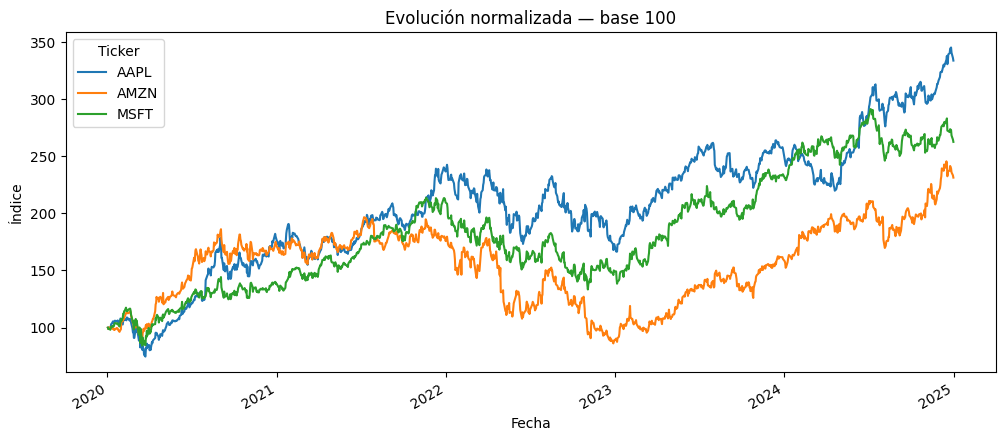

In [18]:
precios_normalizados = precios / precios.iloc[0] * 100

precios_normalizados.plot(figsize=(12, 5))
plt.title("Evolución normalizada — base 100")
plt.xlabel("Fecha")
plt.ylabel("Índice")
plt.show()

# 8. 🔗 Buscar relaciones

En un portafolio no solo importa cómo se comporta cada activo individualmente. También interesa saber cómo se relacionan entre sí.

Primero calculamos los rendimientos de todos los activos.

In [19]:
rendimientos = precios.pct_change()
rendimientos.head()

Ticker,AAPL,AMZN,MSFT
Date,,,
2020-01-02,NaN,NaN,NaN
2020-01-03,-0.009722,-0.012139,-0.012452
2020-01-06,0.007968,0.014886,0.002585
2020-01-07,-0.004703,0.002092,-0.009118
2020-01-08,0.016086,-0.007809,0.015928


In [20]:
correlacion = rendimientos.corr()
correlacion

Ticker,AAPL,AMZN,MSFT
Ticker,,,
AAPL,1.000000,0.591883,0.748121
AMZN,0.591883,1.000000,0.678666
MSFT,0.748121,0.678666,1.000000


### Análisis Financiero de la Matriz de Correlación

La matriz de correlación de los rendimientos es una herramienta fundamental en finanzas para entender la relación entre los movimientos de diferentes activos y es clave para la **diversificación de carteras**.

*   **Correlación Positiva (cercana a +1):** Indica que los rendimientos de los activos tienden a moverse en la misma dirección. Si el rendimiento de un activo sube, es muy probable que el del otro también lo haga, y viceversa. En nuestra matriz, podemos observar una fuerte correlación positiva entre **AAPL y MSFT (0.748)**. Esto significa que si las acciones de Apple suben, las de Microsoft probablemente también lo harán, y si bajan, las de Microsoft también tenderán a bajar. Una correlación alta reduce los beneficios de la diversificación, ya que los activos no actúan como "amortiguadores" el uno del otro en momentos de caída.

*   **Correlación Negativa (cercana a -1):** Sugiere que los rendimientos de los activos tienden a moverse en direcciones opuestas. Si un activo sube, el otro tiende a bajar, y viceversa. Este tipo de correlación es muy deseable para la diversificación, ya que ayuda a mitigar el riesgo de la cartera. En nuestra matriz, no observamos correlaciones negativas fuertes, lo cual es común entre acciones del mismo sector o mercado.

*   **Correlación Cero (cercana a 0):** Implica que no hay una relación lineal predecible entre los movimientos de los rendimientos de los activos. Su comportamiento es independiente el uno del otro. Aunque no reduce el riesgo tan eficazmente como una correlación negativa, sigue siendo beneficioso para la diversificación en comparación con una correlación positiva alta.

#### Implicaciones para la Diversificación:

Para construir un portafolio robusto y diversificado, se busca incluir activos con **baja o negativa correlación**. Esto se debe a que, si un activo experimenta una caída, es probable que otro activo con baja o negativa correlación no caiga (o incluso suba), compensando así parte de la pérdida. Los activos en nuestra matriz muestran correlaciones positivas entre sí, lo que sugiere que son algo dependientes. Por ejemplo, **AAPL** y **AMZN** tienen una correlación de **0.592**, y **AMZN** y **MSFT** de **0.679**. Esto indica que, aunque no se mueven en perfecta sintonía, sus rendimientos sí comparten una tendencia común.

Para mejorar la diversificación, un inversor podría considerar añadir activos de diferentes sectores, geografías o tipos (por ejemplo, bonos, materias primas) que históricamente muestren una correlación más baja o negativa con los activos tecnológicos actuales.

### ¿Cómo podemos leer la correlación?

- Cerca de **1**: los movimientos tienden a ser similares.
- Cerca de **0**: la relación lineal es débil.
- Cerca de **-1**: los movimientos tienden a ser opuestos.

### 💭 Pregunta

Si dos activos presentan una correlación elevada, ¿qué podría significar esto al pensar en diversificación?

# 9. 🚀 Tu análisis

Ahora repite el proceso con los **activos que te fueron asignados**.

Tu análisis debe seguir esta secuencia:

**Obtener → Conocer → Explorar → Transformar → Describir → Comparar → Relacionar → Interpretar**

### Tu misión

1. Obtén los datos históricos desde Yahoo Finance.
2. Explora la estructura del DataFrame.
3. Revisa los datos y los valores faltantes.
4. Observa el comportamiento de los precios.
5. Calcula los rendimientos.
6. Describe los rendimientos con estadísticas.
7. Compara visualmente los activos.
8. Explora la correlación.
9. Escribe una conclusión sustentada en los resultados.

> **Pregunta final:** ¿Qué diferencias encontraste entre los activos y qué información consideras importante conocer antes de incorporarlos a un portafolio?


## ✍️ Mi análisis — activos asignados
**Estudiante:** Valentina

En este taller repito el recorrido de la clase guiada con los activos que me fueron asignados:

**Obtener → Conocer → Explorar → Transformar → Describir → Comparar → Relacionar → Interpretar**

| Ticker | Empresa | Sector |
|---|---|---|
| CSCO | Cisco Systems | Tecnología |
| WFC | Wells Fargo | Financiero |
| PSX | Phillips 66 | Energía (refinación) |
| ABT | Abbott Laboratories | Salud |
| AMZN | Amazon | Consumo discrecional |
| CAT | Caterpillar | Industrial |

Muestra de trabajo: **1 de enero de 2025 a 1 de enero de 2026** (fechas explícitas, igual que en la clase guiada), precios ajustados (`auto_adjust=True`).

> Las interpretaciones numéricas se generan con código a partir de los datos descargados, para que siempre coincidan con los resultados al ejecutar el cuaderno.

### 9.1 🔌 Obtener los datos

In [21]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [22]:
tickers = ["CSCO", "WFC", "PSX", "ABT", "AMZN", "CAT"]

sectores = {
    "CSCO": "Tecnología",
    "WFC": "Financiero",
    "PSX": "Energía",
    "ABT": "Salud",
    "AMZN": "Consumo discrecional",
    "CAT": "Industrial",
}

datos = yf.download(
    tickers,
    start="2025-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

datos.head()

Price         Close                                                High  \
Ticker          ABT     AMZN      CAT    CSCO      PSX     WFC      ABT   
Date                                                                      
2025-01-02 109.2992 220.2200 352.2652 56.5670 108.0106 67.5846 109.8002   
2025-01-03 109.6750 224.1900 356.2013 56.7212 109.5966 68.6630 110.0604   
2025-01-06 108.9138 227.6100 356.6029 56.6345 108.7281 69.3563 110.0893   
2025-01-07 109.2607 222.1100 355.4278 56.7886 108.7470 68.9326 110.5036   
2025-01-08 110.0796 222.1300 353.5381 57.0488 109.7477 68.9134 110.1375   

Price                                 ...     Open                           \
Ticker         AMZN      CAT    CSCO  ...      CAT    CSCO      PSX     WFC   
Date                                  ...                                     
2025-01-02 225.1500 361.1558 57.1221  ... 357.8855 56.7297 108.3410 67.8638   
2025-01-03 225.3600 356.8769 57.0199  ... 354.0472 56.7019 108.9830 67.7387   
2025-01-06 228.8400 363.1044 57.4150  ... 359.3445 56.7694 109.2662 69.2600   
2025-01-07 228.3800 358.4534 57.0970  ... 356.5343 56.8272 109.5872 70.2614   
2025-01-08 223.5200 355.3104 57.0874  ... 354.8893 56.7501 107.6707 68.8556   

Price        Volume                                                  
Ticker          ABT      AMZN      CAT      CSCO      PSX       WFC  
Date                                                                 
2025-01-02  3569100  33956600  1802600  16144300  2538200   8303300  
2025-01-03  4416700  27515600  1390800  18859000  2046000   9152800  
2025-01-06  6037200  31849800  1590700  18543300  2324800  15565600  
2025-01-07  5300100  28084200  1607400  16863800  2526300  13522000  
2025-01-08  4455800  25033300  1828800  14400300  3037100  16544700  

[5 rows x 30 columns]

### 9.2 🧩 Conocer la información
Lo descargado es un **DataFrame de pandas**. Con varios tickers, las columnas tienen dos niveles: el campo (`Open, High, Low, Close, Volume`) y el ticker.

In [23]:
datos.head()

Price         Close                                                High  \
Ticker          ABT     AMZN      CAT    CSCO      PSX     WFC      ABT   
Date                                                                      
2025-01-02 109.2992 220.2200 352.2652 56.5670 108.0106 67.5846 109.8002   
2025-01-03 109.6750 224.1900 356.2013 56.7212 109.5966 68.6630 110.0604   
2025-01-06 108.9138 227.6100 356.6029 56.6345 108.7281 69.3563 110.0893   
2025-01-07 109.2607 222.1100 355.4278 56.7886 108.7470 68.9326 110.5036   
2025-01-08 110.0796 222.1300 353.5381 57.0488 109.7477 68.9134 110.1375   

Price                                 ...     Open                           \
Ticker         AMZN      CAT    CSCO  ...      CAT    CSCO      PSX     WFC   
Date                                  ...                                     
2025-01-02 225.1500 361.1558 57.1221  ... 357.8855 56.7297 108.3410 67.8638   
2025-01-03 225.3600 356.8769 57.0199  ... 354.0472 56.7019 108.9830 67.7387   
2025-01-06 228.8400 363.1044 57.4150  ... 359.3445 56.7694 109.2662 69.2600   
2025-01-07 228.3800 358.4534 57.0970  ... 356.5343 56.8272 109.5872 70.2614   
2025-01-08 223.5200 355.3104 57.0874  ... 354.8893 56.7501 107.6707 68.8556   

Price        Volume                                                  
Ticker          ABT      AMZN      CAT      CSCO      PSX       WFC  
Date                                                                 
2025-01-02  3569100  33956600  1802600  16144300  2538200   8303300  
2025-01-03  4416700  27515600  1390800  18859000  2046000   9152800  
2025-01-06  6037200  31849800  1590700  18543300  2324800  15565600  
2025-01-07  5300100  28084200  1607400  16863800  2526300  13522000  
2025-01-08  4455800  25033300  1828800  14400300  3037100  16544700  

[5 rows x 30 columns]

In [24]:
datos.tail()

Price         Close                                                High  \
Ticker          ABT     AMZN      CAT    CSCO      PSX     WFC      ABT   
Date                                                                      
2025-12-24 122.5328 232.3800 580.2144 76.6019 125.7774 93.7565 123.0433   
2025-12-26 122.5623 232.5200 579.4590 76.7393 125.1309 93.7172 122.9059   
2025-12-29 122.2972 232.0700 575.0956 76.3760 125.9537 92.9892 123.2004   
2025-12-30 123.4851 232.5300 573.8830 76.0029 126.9038 92.7826 123.8974   
2025-12-31 123.0041 230.8200 569.3905 75.6298 126.3944 91.6905 123.9367   

Price                                 ...     Open                           \
Ticker         AMZN      CAT    CSCO  ...      CAT    CSCO      PSX     WFC   
Date                                  ...                                     
2025-12-24 232.9500 583.5639 76.8669  ... 579.1210 76.6019 126.4728 93.1171   
2025-12-26 232.9900 580.2840 76.8571  ... 579.6677 76.6804 125.5913 93.8156   
2025-12-29 232.6000 580.4230 76.8768  ... 576.5666 76.6117 125.9047 93.8156   
2025-12-30 232.7700 577.4512 76.3957  ... 576.4871 76.3957 126.4140 93.1958   
2025-12-31 232.9900 575.4236 76.4055  ... 573.7936 75.9342 127.1389 92.9695   

Price        Volume                                                 
Ticker          ABT      AMZN      CAT      CSCO      PSX      WFC  
Date                                                                
2025-12-24  1632200  11420500   947000   9104400   972000  5506800  
2025-12-26  2120700  15994700   954400  10158000  1317400  5169400  
2025-12-29  4468700  19797900  2585700  17941800  1599500  8624200  
2025-12-30  5271100  21910500  1216700  13952200  1482600  6417800  
2025-12-31  3157100  24383700  1163900  13570500  1339000  7919300  

[5 rows x 30 columns]

In [25]:
print("Dimensiones (filas, columnas):", datos.shape)
print("Campos:", list(datos.columns.get_level_values(0).unique()))
print("Tickers:", list(datos.columns.get_level_values(1).unique()))
print("Primera fecha:", datos.index.min().date())
print("Última fecha:", datos.index.max().date())

Dimensiones (filas, columnas): (250, 30)
Campos: ['Close', 'High', 'Low', 'Open', 'Volume']
Tickers: ['ABT', 'AMZN', 'CAT', 'CSCO', 'PSX', 'WFC']
Primera fecha: 2025-01-02
Última fecha: 2025-12-31


In [26]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 250 entries, 2025-01-02 to 2025-12-31
Data columns (total 30 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, ABT)    250 non-null    float64
 1   (Close, AMZN)   250 non-null    float64
 2   (Close, CAT)    250 non-null    float64
 3   (Close, CSCO)   250 non-null    float64
 4   (Close, PSX)    250 non-null    float64
 5   (Close, WFC)    250 non-null    float64
 6   (High, ABT)     250 non-null    float64
 7   (High, AMZN)    250 non-null    float64
 8   (High, CAT)     250 non-null    float64
 9   (High, CSCO)    250 non-null    float64
 10  (High, PSX)     250 non-null    float64
 11  (High, WFC)     250 non-null    float64
 12  (Low, ABT)      250 non-null    float64
 13  (Low, AMZN)     250 non-null    float64
 14  (Low, CAT)      250 non-null    float64
 15  (Low, CSCO)     250 non-null    float64
 16  (Low, PSX)      250 non-null    float64
 17  (Low, WFC)      

### 🧠 Respuestas — Piensa
- **¿Qué representa una fila?** Un día de negociación en la bolsa (por eso son ~250 filas y no 365: no hay datos en fines de semana ni festivos de EE. UU.).
- **¿Qué representa una columna?** Un campo de precio o volumen para un activo específico, por ejemplo `("Close", "CAT")`. Con 6 tickers × 5 campos se obtienen 30 columnas.
- **¿Qué contiene el índice?** Las fechas (`DatetimeIndex`) de cada sesión.
- **¿Cuántas observaciones tenemos?** Las que muestra `datos.shape[0]` en la celda anterior.

### 9.3 🔎 Mirar antes de calcular
Trabajaremos con el **precio de cierre** (`Close`): el último precio negociado en cada sesión, que resume cómo quedó el activo ese día.

In [27]:
cierre = datos["Close"][tickers]
cierre.describe()

Ticker,CSCO,WFC,PSX,ABT,AMZN,CAT
count,250.0000,250.0000,250.0000,250.0000,250.0000,250.0000
mean,64.6928,76.8444,119.9224,126.1840,217.6728,415.0872
std,6.3365,7.1751,10.9047,5.1606,17.0962,91.9420
min,51.5994,59.0063,88.4654,107.6064,167.3200,269.2090
25%,59.5592,71.9039,114.6023,123.4979,208.0225,344.3338
50%,65.4068,76.7057,120.2337,127.2223,222.1200,395.2857
75%,67.7271,81.6887,127.6087,129.7331,229.6350,480.9086
max,78.7913,93.7565,140.8616,135.8107,254.0000,621.8101


In [28]:
cierre.isna().sum()

,0
Ticker,
CSCO,0
WFC,0
PSX,0
ABT,0
AMZN,0
CAT,0


In [29]:
faltantes = cierre.isna().sum().sum()
if faltantes == 0:
    print("No hay valores faltantes: la muestra está completa para los 6 activos.")
else:
    print(f"Hay {faltantes} valores faltantes. Se revisan por activo:")
    print(cierre.isna().sum())

No hay valores faltantes: la muestra está completa para los 6 activos.


### 🧠 Interpreta
`describe()` sobre los **precios** muestra el nivel (`mean`), el rango (`min`, `max`) y la dispersión (`std`) de cada acción en dólares. Estas cifras **no sirven para comparar activos entre sí**: una acción más cara no significa un mejor desempeño, solo que cada acción cuesta más. Por eso más adelante pasamos a rendimientos.

### 9.4 📈 Observar el comportamiento de los precios

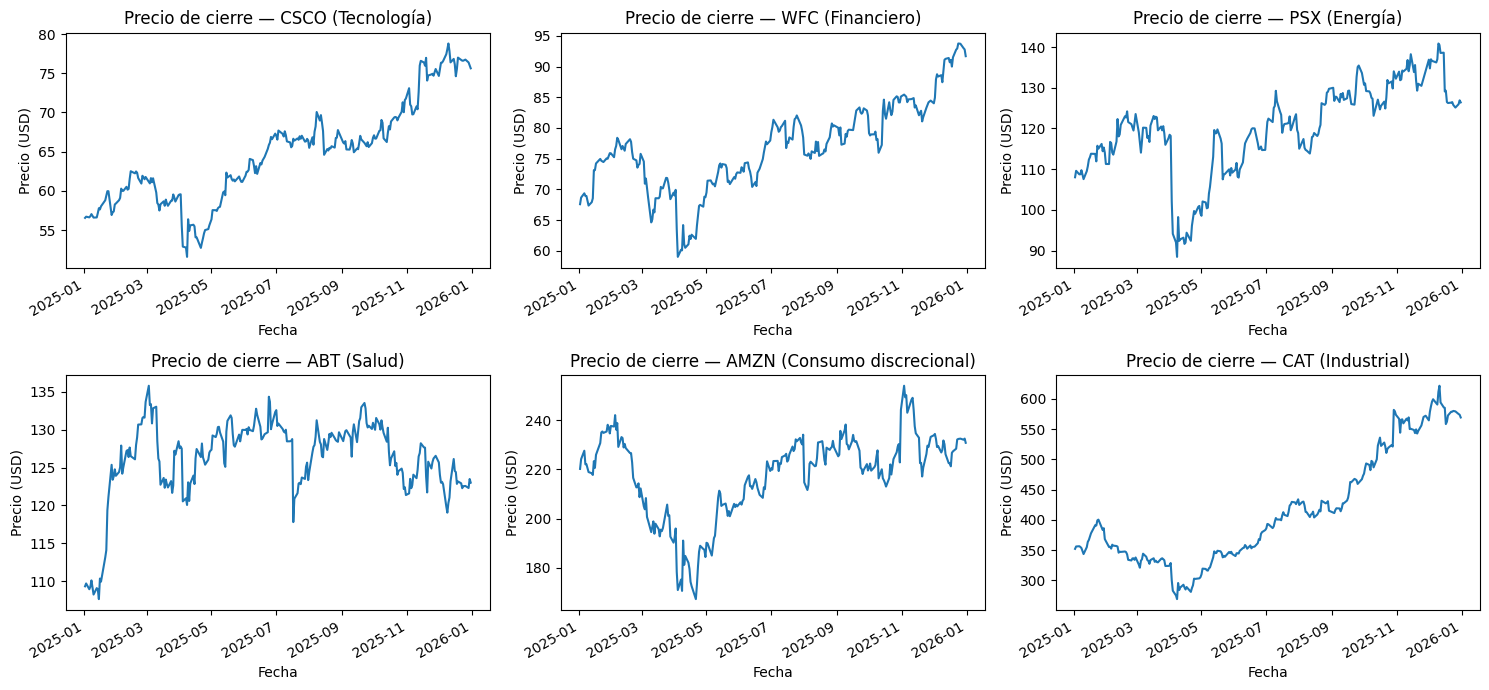

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, t in zip(axes.flat, tickers):
    cierre[t].plot(ax=ax)
    ax.set_title(f"Precio de cierre — {t} ({sectores[t]})")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Precio (USD)")
plt.tight_layout()
plt.show()

In [31]:
resumen_precio = pd.DataFrame({
    "Precio inicial": cierre.iloc[0],
    "Precio final": cierre.iloc[-1],
    "Precio mínimo": cierre.min(),
    "Precio máximo": cierre.max(),
})
resumen_precio["Variación anual (%)"] = (resumen_precio["Precio final"] / resumen_precio["Precio inicial"] - 1) * 100
resumen_precio.sort_values("Variación anual (%)", ascending=False)

,Precio inicial,Precio final,Precio mínimo,Precio máximo,Variación anual (%)
Ticker,,,,,
CAT,352.2652,569.3905,269.2090,621.8101,61.6369
WFC,67.5846,91.6905,59.0063,93.7565,35.6678
CSCO,56.5670,75.6298,51.5994,78.7913,33.6996
PSX,108.0106,126.3944,88.4654,140.8616,17.0204
ABT,109.2992,123.0041,107.6064,135.8107,12.5388
AMZN,220.2200,230.8200,167.3200,254.0000,4.8134


In [32]:
# Interpretación automática de la tendencia
def tendencia(var):
    if var > 5:
        return "al alza"
    elif var < -5:
        return "a la baja"
    return "estable / lateral"

for t in tickers:
    var = resumen_precio.loc[t, "Variación anual (%)"]
    print(f"{t}: tendencia {tendencia(var)} en el año ({var:+.2f}%), "
          f"con un rango entre {resumen_precio.loc[t, 'Precio mínimo']:.2f} y {resumen_precio.loc[t, 'Precio máximo']:.2f} USD.")

CSCO: tendencia al alza en el año (+33.70%), con un rango entre 51.60 y 78.79 USD.
WFC: tendencia al alza en el año (+35.67%), con un rango entre 59.01 y 93.76 USD.
PSX: tendencia al alza en el año (+17.02%), con un rango entre 88.47 y 140.86 USD.
ABT: tendencia al alza en el año (+12.54%), con un rango entre 107.61 y 135.81 USD.
AMZN: tendencia estable / lateral en el año (+4.81%), con un rango entre 167.32 y 254.00 USD.
CAT: tendencia al alza en el año (+61.64%), con un rango entre 269.21 y 621.81 USD.


### 👀 Observa
Las gráficas permiten identificar períodos de crecimiento y caída, y cambios bruscos. En abril de 2025 conviene fijarse si hubo una caída generalizada (el mercado estadounidense reaccionó con fuerza a los anuncios de aranceles), y ver qué activos se recuperaron más rápido después.

### 9.5 🔄 Medir los cambios: rendimientos
$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$
El rendimiento sí permite comparar activos con precios muy distintos, porque mide el cambio en proporción a lo que valía antes.

In [33]:
rendimientos = cierre.pct_change()
rendimientos.head()

Ticker,CSCO,WFC,PSX,ABT,AMZN,CAT
Date,,,,,,
2025-01-02,NaN,NaN,NaN,NaN,NaN,NaN
2025-01-03,0.0027,0.0160,0.0147,0.0034,0.0180,0.0112
2025-01-06,-0.0015,0.0101,-0.0079,-0.0069,0.0153,0.0011
2025-01-07,0.0027,-0.0061,0.0002,0.0032,-0.0242,-0.0033
2025-01-08,0.0046,-0.0003,0.0092,0.0075,0.0001,-0.0053


El primer valor es `NaN` porque el primer día no tiene un día anterior con el cual compararse. Se elimina para las estadísticas.

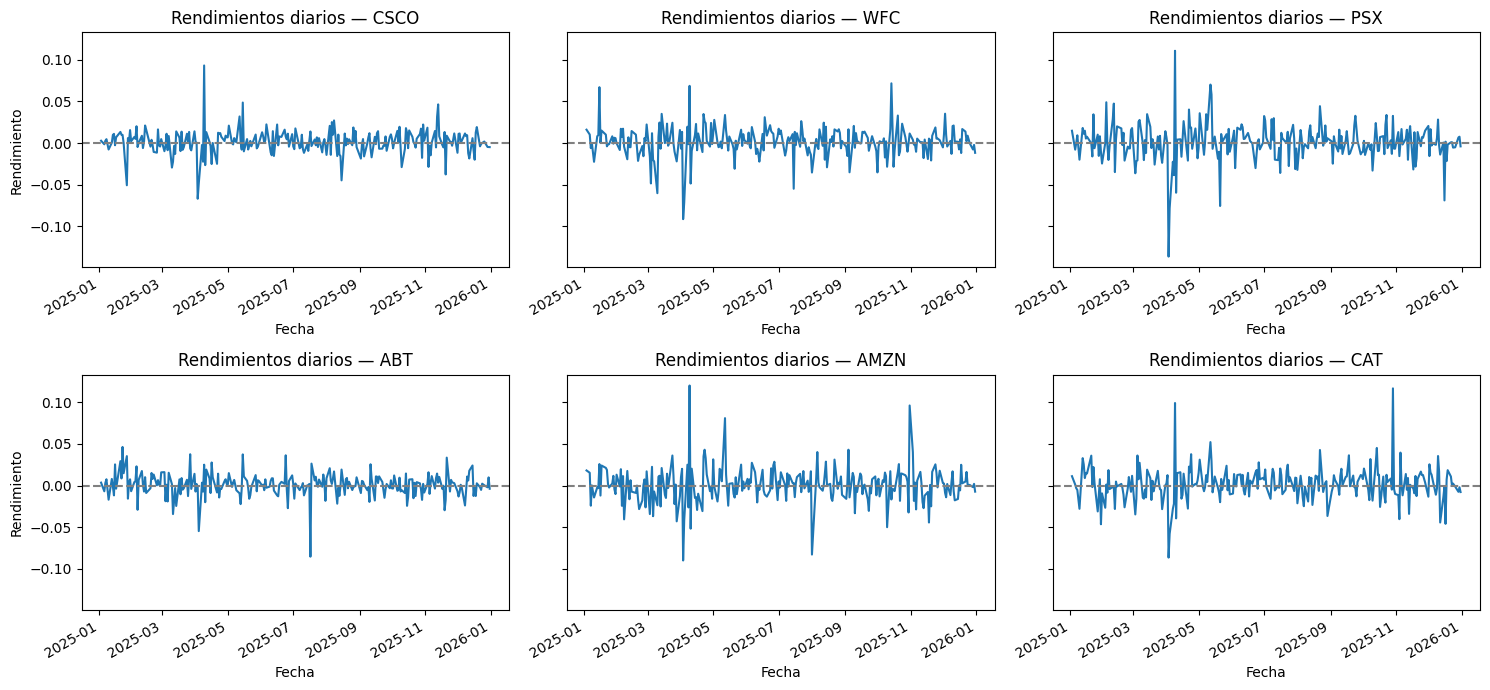

In [34]:
rendimientos = rendimientos.dropna()

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.flat, tickers):
    rendimientos[t].plot(ax=ax)
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(f"Rendimientos diarios — {t}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Rendimiento")
plt.tight_layout()
plt.show()

Las seis series **oscilan alrededor de cero**, sin una dirección fija, a diferencia de los precios. Al usar el mismo eje vertical (`sharey=True`) se ve de inmediato cuáles activos tienen picos más amplios, es decir, más volatilidad.

### 9.6 📐 Describir los rendimientos

In [35]:
rendimientos.describe()

Ticker,CSCO,WFC,PSX,ABT,AMZN,CAT
count,249.0000,249.0000,249.0000,249.0000,249.0000,249.0000
mean,0.0013,0.0014,0.0009,0.0006,0.0004,0.0021
std,0.0150,0.0184,0.0224,0.0140,0.0217,0.0202
min,-0.0668,-0.0912,-0.1361,-0.0852,-0.0898,-0.0864
25%,-0.0053,-0.0064,-0.0093,-0.0057,-0.0112,-0.0075
50%,0.0010,0.0020,0.0013,0.0010,0.0006,0.0012
75%,0.0099,0.0114,0.0129,0.0075,0.0124,0.0125
max,0.0929,0.0715,0.1105,0.0462,0.1198,0.1163


In [36]:
estadisticas = pd.DataFrame({
    "Promedio diario": rendimientos.mean(),
    "Desv. estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Fecha peor día": rendimientos.idxmin().dt.date,
    "Máximo": rendimientos.max(),
    "Fecha mejor día": rendimientos.idxmax().dt.date,
    "Percentil 1%": rendimientos.quantile(0.01),
    "Percentil 5%": rendimientos.quantile(0.05),
})
estadisticas["Volatilidad anualizada"] = estadisticas["Desv. estándar"] * np.sqrt(252)
estadisticas.sort_values("Desv. estándar")

,Promedio diario,Desv. estándar,Mínimo,Fecha peor día,Máximo,Fecha mejor día,Percentil 1%,Percentil 5%,Volatilidad anualizada
Ticker,,,,,,,,,
ABT,0.0006,0.0140,-0.0852,2025-07-17,0.0462,2025-01-23,-0.0320,-0.0194,0.2216
CSCO,0.0013,0.0150,-0.0668,2025-04-03,0.0929,2025-04-09,-0.0466,-0.0214,0.2379
WFC,0.0014,0.0184,-0.0912,2025-04-03,0.0715,2025-10-14,-0.0575,-0.0260,0.2914
CAT,0.0021,0.0202,-0.0864,2025-04-03,0.1163,2025-10-29,-0.0462,-0.0280,0.3204
AMZN,0.0004,0.0217,-0.0898,2025-04-03,0.1198,2025-04-09,-0.0508,-0.0305,0.3449
PSX,0.0009,0.0224,-0.1361,2025-04-03,0.1105,2025-04-09,-0.0722,-0.0308,0.3563


In [37]:
for t in tickers:
    e = estadisticas.loc[t]
    print(f"--- {t} ({sectores[t]}) ---")
    print(f"Promedio diario: {e['Promedio diario']:.4%} | Desv. estándar: {e['Desv. estándar']:.4%}")
    print(f"La desviación estándar es {e['Desv. estándar'] / abs(e['Promedio diario']):.0f} veces el promedio (en valor absoluto): "
          "el promedio esconde movimientos diarios fuertes.")
    print(f"Peor día: {e['Mínimo']:.2%} ({e['Fecha peor día']}) | Mejor día: {e['Máximo']:.2%} ({e['Fecha mejor día']})")
    print(f"VaR histórico 95%: en 1 de cada 20 días la pérdida fue de {abs(e['Percentil 5%']):.2%} o más.")
    print(f"VaR histórico 99%: en 1 de cada 100 días la pérdida fue de {abs(e['Percentil 1%']):.2%} o más.\n")

--- CSCO (Tecnología) ---
Promedio diario: 0.1279% | Desv. estándar: 1.4984%
La desviación estándar es 12 veces el promedio (en valor absoluto): el promedio esconde movimientos diarios fuertes.
Peor día: -6.68% (2025-04-03) | Mejor día: 9.29% (2025-04-09)
VaR histórico 95%: en 1 de cada 20 días la pérdida fue de 2.14% o más.
VaR histórico 99%: en 1 de cada 100 días la pérdida fue de 4.66% o más.

--- WFC (Financiero) ---
Promedio diario: 0.1395% | Desv. estándar: 1.8359%
La desviación estándar es 13 veces el promedio (en valor absoluto): el promedio esconde movimientos diarios fuertes.
Peor día: -9.12% (2025-04-03) | Mejor día: 7.15% (2025-10-14)
VaR histórico 95%: en 1 de cada 20 días la pérdida fue de 2.60% o más.
VaR histórico 99%: en 1 de cada 100 días la pérdida fue de 5.75% o más.

--- PSX (Energía) ---
Promedio diario: 0.0885% | Desv. estándar: 2.2445%
La desviación estándar es 25 veces el promedio (en valor absoluto): el promedio esconde movimientos diarios fuertes.
Peor día: -

### 🧠 Interpreta
- **Promedio:** cercano a cero en todos los casos; día a día, en general, no se gana ni se pierde mucho.
- **Desviación estándar:** mide la volatilidad. Es mucho mayor que el promedio, lo que confirma lo que muestra la gráfica: hubo días con movimientos fuertes en ambas direcciones.
- **Mínimo y máximo:** el peor y el mejor día del año. Muestran los choques extremos que el promedio no deja ver.
- **Percentiles 1% y 5%:** se leen como una pérdida histórica de referencia (VaR) con 99% y 95% de confianza.

### 🎫 Exit ticket (por activo)
«Mi ticker asignado fue ___. El precio mostró una tendencia ___ durante el año. El rendimiento promedio diario fue ___ y la desviación estándar ___. El peor día tuvo un rendimiento de ___.»

In [38]:
for t in tickers:
    var = resumen_precio.loc[t, "Variación anual (%)"]
    e = estadisticas.loc[t]
    print(f"Mi ticker asignado fue {t}. El precio mostró una tendencia {tendencia(var)} durante el año ({var:+.2f}%). "
          f"El rendimiento promedio diario fue {e['Promedio diario']:.4%} y la desviación estándar {e['Desv. estándar']:.4%}. "
          f"El peor día tuvo un rendimiento de {e['Mínimo']:.2%} ({e['Fecha peor día']}).\n")

Mi ticker asignado fue CSCO. El precio mostró una tendencia al alza durante el año (+33.70%). El rendimiento promedio diario fue 0.1279% y la desviación estándar 1.4984%. El peor día tuvo un rendimiento de -6.68% (2025-04-03).

Mi ticker asignado fue WFC. El precio mostró una tendencia al alza durante el año (+35.67%). El rendimiento promedio diario fue 0.1395% y la desviación estándar 1.8359%. El peor día tuvo un rendimiento de -9.12% (2025-04-03).

Mi ticker asignado fue PSX. El precio mostró una tendencia al alza durante el año (+17.02%). El rendimiento promedio diario fue 0.0885% y la desviación estándar 2.2445%. El peor día tuvo un rendimiento de -13.61% (2025-04-03).

Mi ticker asignado fue ABT. El precio mostró una tendencia al alza durante el año (+12.54%). El rendimiento promedio diario fue 0.0572% y la desviación estándar 1.3959%. El peor día tuvo un rendimiento de -8.52% (2025-07-17).

Mi ticker asignado fue AMZN. El precio mostró una tendencia estable / lateral durante el a

### 9.7 ⚖️ Comparar los activos
Los precios tienen escalas distintas, así que los llevamos a **base 100**: $P_{t,norm} = \frac{P_t}{P_0} \times 100$

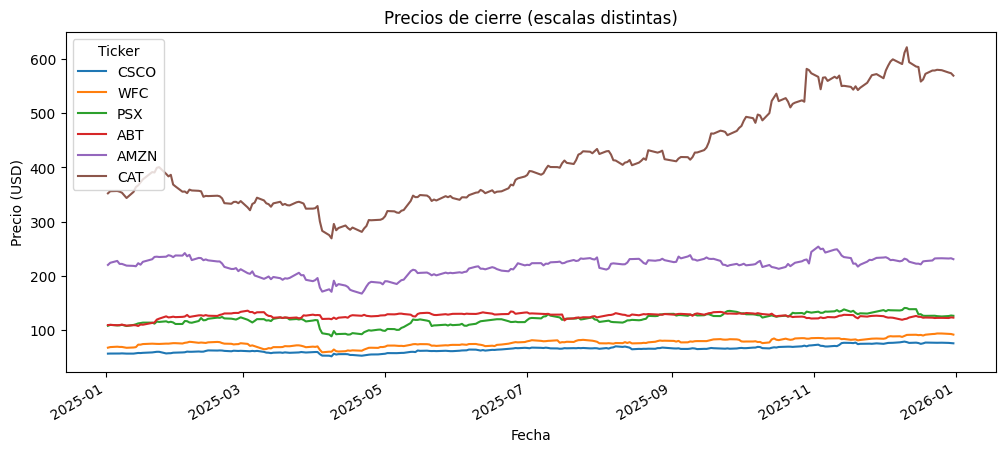

In [39]:
cierre.plot(figsize=(12, 5))
plt.title("Precios de cierre (escalas distintas)")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.show()

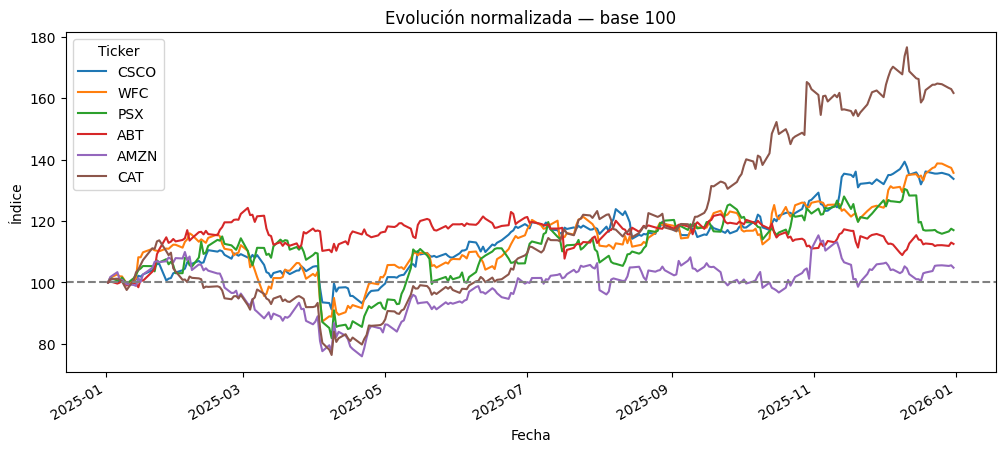

,Valor final (base 100)
Ticker,
CAT,161.6400
WFC,135.6700
CSCO,133.7000
PSX,117.0200
ABT,112.5400
AMZN,104.8100


In [40]:
base100 = cierre / cierre.iloc[0] * 100

base100.plot(figsize=(12, 5))
plt.axhline(100, color="gray", linestyle="--")
plt.title("Evolución normalizada — base 100")
plt.xlabel("Fecha")
plt.ylabel("Índice")
plt.show()

base100.iloc[-1].sort_values(ascending=False).round(2).rename("Valor final (base 100)")

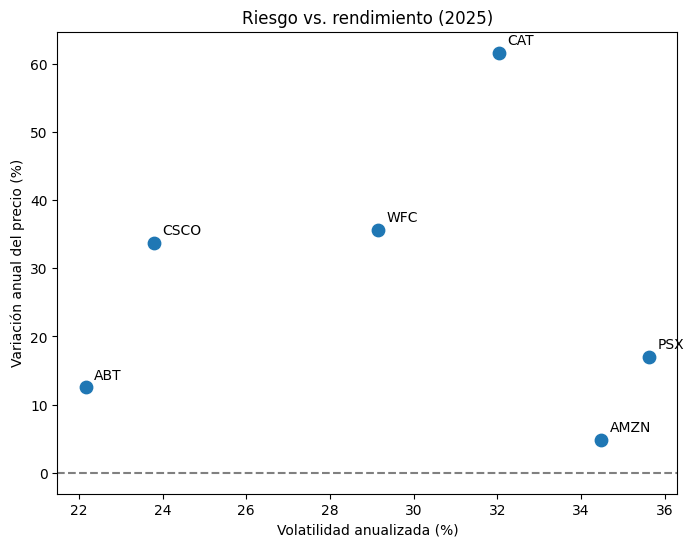

In [41]:
# Riesgo vs. rendimiento: ¿quién ganó más y a cambio de cuánta volatilidad?
x = estadisticas["Volatilidad anualizada"] * 100
y = resumen_precio["Variación anual (%)"]

plt.figure(figsize=(8, 6))
plt.scatter(x, y, s=80)
for t in tickers:
    plt.annotate(t, (x[t], y[t]), textcoords="offset points", xytext=(6, 6))
plt.axhline(0, color="gray", linestyle="--")
plt.title("Riesgo vs. rendimiento (2025)")
plt.xlabel("Volatilidad anualizada (%)")
plt.ylabel("Variación anual del precio (%)")
plt.show()

In [42]:
mejor = y.idxmax(); peor = y.idxmin()
mas_vol = x.idxmax(); menos_vol = x.idxmin()
print(f"Mayor crecimiento en el año: {mejor} ({y[mejor]:+.2f}%)")
print(f"Menor crecimiento en el año: {peor} ({y[peor]:+.2f}%)")
print(f"Más volátil: {mas_vol} ({x[mas_vol]:.2f}% anualizado)")
print(f"Menos volátil: {menos_vol} ({x[menos_vol]:.2f}% anualizado)")

Mayor crecimiento en el año: CAT (+61.64%)
Menor crecimiento en el año: AMZN (+4.81%)
Más volátil: PSX (35.63% anualizado)
Menos volátil: ABT (22.16% anualizado)


### 9.8 🔗 Buscar relaciones: correlación
- Cerca de **1**: se mueven en la misma dirección.
- Cerca de **0**: relación lineal débil.
- Cerca de **-1**: se mueven en direcciones opuestas.

In [43]:
correlacion = rendimientos.corr()
correlacion

Ticker,CSCO,WFC,PSX,ABT,AMZN,CAT
Ticker,,,,,,
CSCO,1.0000,0.4983,0.4077,0.1662,0.4572,0.4767
WFC,0.4983,1.0000,0.4967,0.1384,0.5076,0.5131
PSX,0.4077,0.4967,1.0000,0.1854,0.4385,0.5423
ABT,0.1662,0.1384,0.1854,1.0000,-0.0042,0.0661
AMZN,0.4572,0.5076,0.4385,-0.0042,1.0000,0.4921
CAT,0.4767,0.5131,0.5423,0.0661,0.4921,1.0000


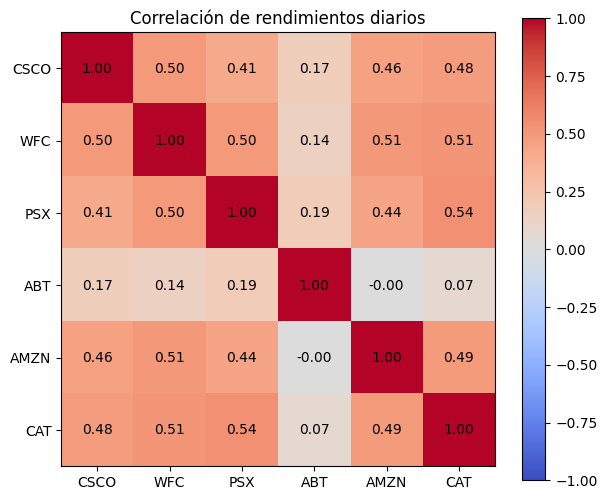

In [44]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(tickers)), tickers)
ax.set_yticks(range(len(tickers)), tickers)
for i in range(len(tickers)):
    for j in range(len(tickers)):
        ax.text(j, i, f"{correlacion.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax)
ax.set_title("Correlación de rendimientos diarios")
plt.show()

In [45]:
# Pares ordenados (sin repetir ni incluir la diagonal)
mascara = np.triu(np.ones(correlacion.shape, dtype=bool), k=1)
pares = correlacion.where(mascara).stack().dropna().sort_values(ascending=False)
pares.index = [f"{a} - {b}" for a, b in pares.index]

print("Pares más correlacionados:")
print(pares.head(3).round(3).to_string())
print("\nPares menos correlacionados:")
print(pares.tail(3).round(3).to_string())
print(f"\nCorrelación promedio entre pares: {pares.mean():.3f}")
print("\nCorrelación promedio de cada activo con los demás:")
print(((correlacion.sum() - 1) / (len(tickers) - 1)).sort_values().round(3).to_string())

Pares más correlacionados:
PSX - CAT    0.5420
WFC - CAT    0.5130
WFC - AMZN   0.5080

Pares menos correlacionados:
WFC - ABT     0.1380
ABT - CAT     0.0660
ABT - AMZN   -0.0040

Correlación promedio entre pares: 0.359

Correlación promedio de cada activo con los demás:
Ticker
ABT    0.1100
AMZN   0.3780
CSCO   0.4010
PSX    0.4140
CAT    0.4180
WFC    0.4310


### 💭 Pregunta
**Si dos activos presentan una correlación elevada, ¿qué significa para la diversificación?**  
Que tienden a subir y caer juntos, así que tenerlos a ambos aporta poca protección: cuando uno cae, el otro probablemente también. Para diversificar conviene combinar activos con correlación baja, porque sus caídas no coinciden y unos amortiguan a otros. Aunque mis seis activos son de sectores distintos, todos son acciones de EE. UU. y comparten el riesgo de mercado, por eso es de esperar que las correlaciones sean positivas.

### 9.9 🚀 Conclusión

In [46]:
mas_corr = pares.index[0]; menos_corr = pares.index[-1]
if pares.mean() >= 0.5:
    lectura_corr = "alta: los activos tienden a moverse juntos y la diversificación es limitada"
elif pares.mean() >= 0.2:
    lectura_corr = "positiva moderada: todos responden al mercado estadounidense, pero la mezcla de sectores evita que se muevan igual"
else:
    lectura_corr = "baja: los activos se mueven de forma bastante independiente, lo que favorece la diversificación"
print(f"""CONCLUSIÓN (generada con los resultados):

1. Desempeño: en 2025 el activo con mayor crecimiento fue {mejor} ({y[mejor]:+.2f}%) y el de menor
   crecimiento fue {peor} ({y[peor]:+.2f}%). Comparar precios absolutos no permitía ver esto; la base 100 sí.

2. Riesgo: el activo más volátil fue {mas_vol} ({x[mas_vol]:.1f}% anualizado) y el más estable fue
   {menos_vol} ({x[menos_vol]:.1f}%). En todos, el rendimiento promedio diario es casi cero y la
   desviación estándar es muchas veces mayor, por lo que el promedio solo no describe el riesgo.

3. Relaciones: el par más correlacionado fue {mas_corr} ({pares.iloc[0]:.2f}) y el menos correlacionado
   {menos_corr} ({pares.iloc[-1]:.2f}). La correlación promedio fue {pares.mean():.2f}, {lectura_corr}.

4. Para un portafolio: combinar {menos_corr.replace(' - ', ' y ')} aporta más diversificación que combinar {mas_corr.replace(' - ', ' y ')}.
""")

CONCLUSIÓN (generada con los resultados):

1. Desempeño: en 2025 el activo con mayor crecimiento fue CAT (+61.64%) y el de menor
   crecimiento fue AMZN (+4.81%). Comparar precios absolutos no permitía ver esto; la base 100 sí.

2. Riesgo: el activo más volátil fue PSX (35.6% anualizado) y el más estable fue
   ABT (22.2%). En todos, el rendimiento promedio diario es casi cero y la
   desviación estándar es muchas veces mayor, por lo que el promedio solo no describe el riesgo.

3. Relaciones: el par más correlacionado fue PSX - CAT (0.54) y el menos correlacionado
   ABT - AMZN (-0.00). La correlación promedio fue 0.36, positiva moderada: todos responden al mercado estadounidense, pero la mezcla de sectores evita que se muevan igual.

4. Para un portafolio: combinar ABT y AMZN aporta más diversificación que combinar PSX y CAT.



### Pregunta final
**¿Qué diferencias encontré entre los activos y qué información es importante conocer antes de incorporarlos a un portafolio?**

Las diferencias aparecen en tres dimensiones: **cuánto crecieron** (variación anual y base 100), **cuánto riesgo asumieron** (desviación estándar, peor día y percentiles) y **cómo se mueven entre sí** (correlación). Antes de incorporarlos a un portafolio es importante conocer las tres al mismo tiempo: un activo con alto crecimiento puede venir acompañado de alta volatilidad, y dos activos atractivos por separado pueden aportar poca diversificación si están muy correlacionados. También hay que recordar que esto es una **muestra de un solo año**: los resultados pueden cambiar con otro período, así que no deben tomarse como una predicción.

## 🎫 Salida de aprendizaje

Completa estas tres frases en una celda de texto:

- **Encontré que…**
- **La información que más me ayudó a comparar los activos fue…**
- **Antes de construir un portafolio, considero importante revisar…**


In [47]:
print(f"Encontré que, aunque los seis activos son de sectores distintos, sus rendimientos diarios oscilan alrededor de cero "
      f"y difieren sobre todo en volatilidad (de {x[menos_vol]:.1f}% en {menos_vol} a {x[mas_vol]:.1f}% en {mas_vol}) "
      f"y en su crecimiento anual (de {y[peor]:+.1f}% en {peor} a {y[mejor]:+.1f}% en {mejor}).\n")
print("La información que más me ayudó a comparar los activos fue la normalización en base 100 junto con la desviación "
      "estándar de los rendimientos, porque ponen a todos los activos en la misma escala sin importar su precio.\n")
print("Antes de construir un portafolio, considero importante revisar la volatilidad, las pérdidas extremas (peor día y "
      "percentiles) y la correlación entre los activos, no solo cuánto subió cada uno.")

Encontré que, aunque los seis activos son de sectores distintos, sus rendimientos diarios oscilan alrededor de cero y difieren sobre todo en volatilidad (de 22.2% en ABT a 35.6% en PSX) y en su crecimiento anual (de +4.8% en AMZN a +61.6% en CAT).

La información que más me ayudó a comparar los activos fue la normalización en base 100 junto con la desviación estándar de los rendimientos, porque ponen a todos los activos en la misma escala sin importar su precio.

Antes de construir un portafolio, considero importante revisar la volatilidad, las pérdidas extremas (peor día y percentiles) y la correlación entre los activos, no solo cuánto subió cada uno.
